## Stellar-property pilot

## 1. Scatter diagrams by class

2079 stars, 8 classes


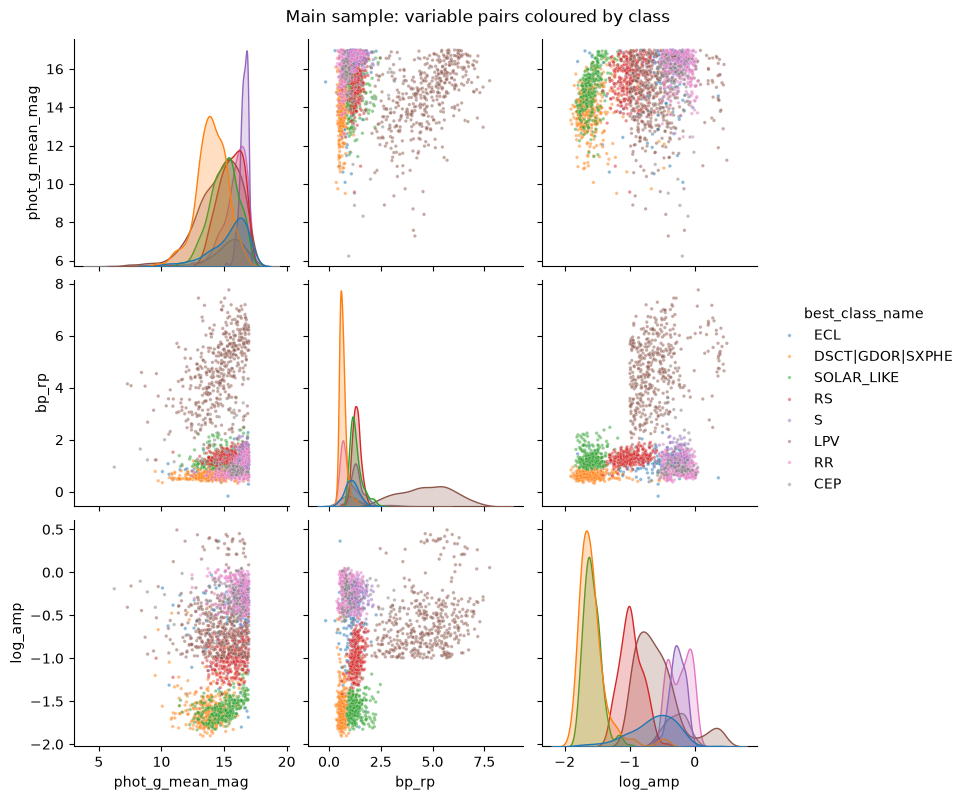

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

c = pd.read_csv("../data/processed/classified_sample_flagged.csv")
m = c[c["main_sample"] & (c["best_class_name"] != "CV")].copy()
m["log_amp"] = np.log10(m["trimmed_range_mag_g_fov"])
print(len(m), "stars,", m["best_class_name"].nunique(), "classes")

cols = ["phot_g_mean_mag", "bp_rp", "log_amp"]
g = sns.pairplot(m, vars=cols, hue="best_class_name",
                 plot_kws={"s": 6, "alpha": 0.5}, diag_kind="kde", height=2.6)
g.figure.suptitle("Main sample: variable pairs coloured by class", y=1.02)
plt.show()

In [4]:
from astroquery.gaia import Gaia

t = Gaia.load_table("gaiadr3.astrophysical_parameters")
keys = ("teff", "lum", "radius", "logg", "mg_", "ag_")
print([col.name for col in t.columns if any(k in col.name for k in keys)])

['teff_gspphot', 'teff_gspphot_lower', 'teff_gspphot_upper', 'logg_gspphot', 'logg_gspphot_lower', 'logg_gspphot_upper', 'ag_gspphot', 'ag_gspphot_lower', 'ag_gspphot_upper', 'mg_gspphot', 'mg_gspphot_lower', 'mg_gspphot_upper', 'radius_gspphot', 'radius_gspphot_lower', 'radius_gspphot_upper', 'teff_gspspec', 'teff_gspspec_lower', 'teff_gspspec_upper', 'logg_gspspec', 'logg_gspspec_lower', 'logg_gspspec_upper', 'ag_esphs', 'ag_esphs_uncertainty', 'teff_esphs', 'teff_esphs_uncertainty', 'logg_esphs', 'logg_esphs_uncertainty', 'teff_espucd', 'teff_espucd_uncertainty', 'radius_flame', 'radius_flame_lower', 'radius_flame_upper', 'lum_flame', 'lum_flame_lower', 'lum_flame_upper', 'teff_msc1', 'teff_msc1_upper', 'teff_msc1_lower', 'teff_msc2', 'teff_msc2_upper', 'teff_msc2_lower', 'logg_msc1', 'logg_msc1_upper', 'logg_msc1_lower', 'logg_msc2', 'logg_msc2_upper', 'logg_msc2_lower', 'ag_msc', 'ag_msc_upper', 'ag_msc_lower']


## 2. Stellar-property pilot

In [7]:
import pandas as pd
from astroquery.gaia import Gaia
from datetime import date

rr_a = pd.read_csv("../data/raw/gaia_dr3_rrlyrae_sample_ri20M_raw.csv")
ids = rr_a["source_id"].head(300).tolist()
id_list = ",".join(str(i) for i in ids)

q = f"""
SELECT source_id, teff_gspphot, radius_gspphot, mg_gspphot, ag_gspphot,
       radius_flame, lum_flame
FROM gaiadr3.astrophysical_parameters
WHERE source_id IN ({id_list})
"""
ap = Gaia.launch_job(q).get_results().to_pandas()
print("Query date:", date.today(), "| Release: Gaia DR3")
print(len(ap), "of", len(ids), "stars have a row in astrophysical_parameters")

ap = rr_a.head(300).merge(ap, on="source_id", how="left")
print(ap[["teff_gspphot", "radius_gspphot", "mg_gspphot", "ag_gspphot", "radius_flame", "lum_flame"]].isna().mean().round(3))
print(ap[["teff_gspphot", "radius_gspphot", "mg_gspphot", "lum_flame"]].describe().round(2))

Query date: 2026-10-15 | Release: Gaia DR3
294 of 300 stars have a row in astrophysical_parameters
teff_gspphot      0.627
radius_gspphot    0.627
mg_gspphot        0.627
ag_gspphot        0.627
radius_flame      0.810
lum_flame         0.810
dtype: float64
       teff_gspphot  radius_gspphot  mg_gspphot  lum_flame
count        112.00          112.00      112.00      57.00
mean        6351.88            1.30        4.34      18.62
std         1429.59            0.94        1.98      40.99
min         3612.21            0.28       -0.38       0.21
25%         5646.84            0.64        2.72       1.86
50%         6127.32            0.97        4.58       6.72
75%         6574.61            1.64        5.72      20.31
max        11930.97            5.48        9.82     280.64


## Stellar-property pilot (Gaia astrophysical_parameters)

Pilot on the first 300 stars of the reproducible RR Lyrae sample (Gaia DR3, queried 2026-10-15). 294 have a row in the table, but GSP-Phot temperature, radius, absolute magnitude and extinction are missing for 62.7% (112 of 300 present), and FLAME radius and luminosity for 81.0% (57 present). Present values include implausible ones for RR Lyrae (M_G from -0.38 to 9.82, luminosity up to 280). Decision: these parameters are not used; colour (bp_rp) and G magnitude remain the stellar-property stand-ins. This is a limitation of the catalogue, not a finding about the stars.